In [133]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from scipy import stats
from IPython.display import display, Math

In [134]:
df = pd.read_csv('data.csv', index_col='t')
df

,x
t,
1937.0,8.0
1938.0,30.0
1939.0,81.0
1940.0,282.0
1941.0,641.0
1942.0,1194.0
1943.0,1898.0


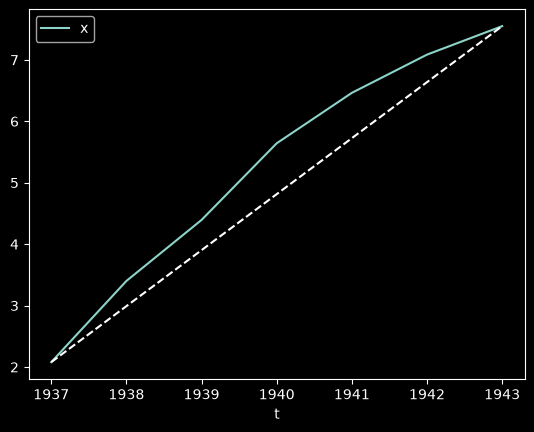

In [135]:
log_df = np.log(df)
log_df.plot()
plt.plot(list(log_df.index[::len(df)-1]), list(log_df.x[::len(df)-1]), 
            color='white', linestyle='--')

*В данной популяции фазанов наблюдается плотностно-зависимый рост численности*

<IPython.core.display.Math object>

Оценка K: 1997.32


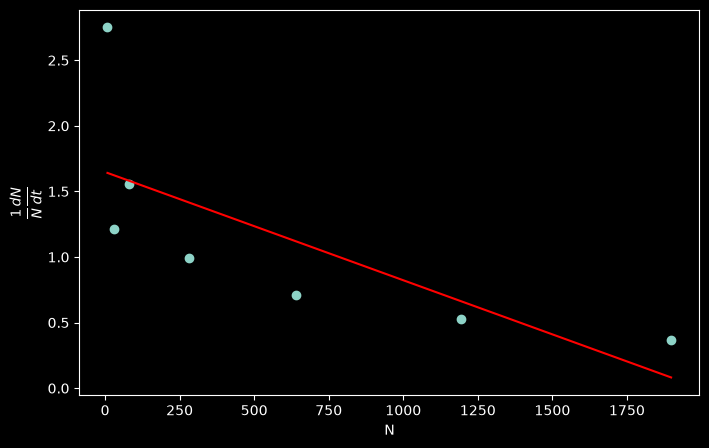

In [136]:
x = df['x'].values.astype(float)
t = df.index.values.astype(float)

# Центральные разности
dxdt = np.zeros_like(x)
for i in range(1, len(x)-1):
    dxdt[i] = (x[i+1] - x[i-1]) / (t[i+1] - t[i-1])

# Односторонние разности
dxdt[0] = (x[1] - x[0]) / (t[1] - t[0])
dxdt[-1] = (x[-1] - x[-2]) / (t[-1] - t[-2])

# Удельная скорость роста
specific_growth = dxdt / x

slope, intercept, r_value, p_value, std_err = stats.linregress(x, specific_growth)

display(Math(f'Уравнение ~ регрессии: ' + f'y = {intercept:.6f} {slope:.6f} \\cdot x'))

K_est = -intercept / slope
print(f'Оценка K: {K_est:.2f}')

plt.figure(figsize=(8, 5))
plt.plot(x, specific_growth, 'o')
plt.plot(x, intercept + slope*x, 'r-')

plt.xlabel('N')
plt.ylabel('$\\dfrac{1}{N}\\dfrac{dN}{dt}$')

plt.show()

<IPython.core.display.Math object>

Оценка r: 1.320432


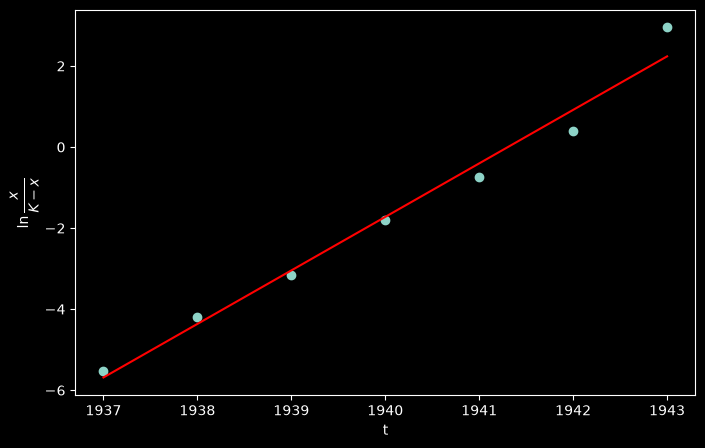

In [137]:
K = K_est

logit_x = np.log(x / (K - x))

slope_r, intercept_r, r_value_r, p_value_r, std_err_r = stats.linregress(t, logit_x)

display(Math(
    'Регрессия: '
    + r'\ln \dfrac{x}{K-x} = '
    + f'{intercept_r:.4f} + ({slope_r:.6f})'
    + r'\cdot t'
))
print(f'Оценка r: {slope_r:.6f}')

plt.figure(figsize=(8, 5))
plt.plot(t, logit_x, 'o')
plt.plot(t, intercept_r + slope_r * t, 'r-')
plt.xlabel('t')
plt.ylabel('$\\ln {\\dfrac{x}{K-x}}$')

plt.show()

In [138]:
print(f'Ресурсный параметр K ≈ {K_est:.0f}')
print(f'Мальтузианский параметр r ≈ {slope_r:.4f}')

Ресурсный параметр K ≈ 1997
Мальтузианский параметр r ≈ 1.3204


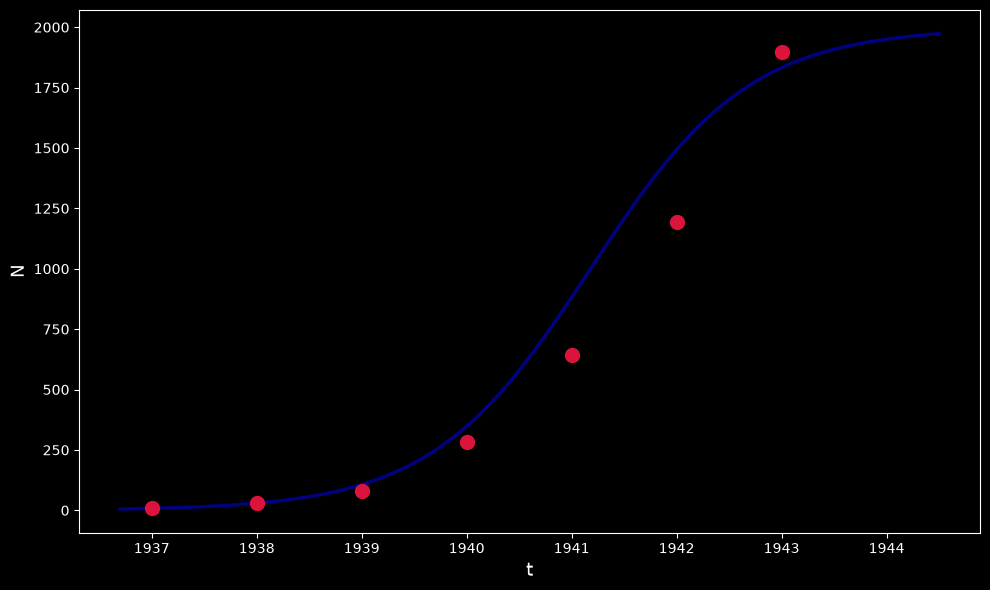

In [139]:
x0 = x[0]
t0 = t[0]

def logistic(t, r, K, x0, t0):
    return K / (1 + (K/x0 - 1) * np.exp(-r * (t - t0)))

t_smooth = np.linspace(t[0] - 0.3, t[-1] + 1.5, 500)
x_smooth = logistic(t_smooth, slope_r, K_est, x0, t0)

x_model = logistic(t, slope_r, K_est, x0, t0)

plt.figure(figsize=(10, 6))

plt.plot(t, x, 'o', color='crimson', ms=10, zorder=5)

plt.plot(t_smooth, x_smooth, '-', color='navy', lw=2.5)

plt.xlabel('t', fontsize=13)
plt.ylabel('N', fontsize=13)

plt.tight_layout()
plt.show()